# Advanced Sports Business Analytics & Data Mining Pipeline
### Comprehensive Academic Submission & Technical Report
**Project:** Forbes Most Valuable Sports Teams Global Valuation Analysis  
**Framework:** End-to-End Data Science & Knowledge Discovery in Databases (KDD)  
**Deterministic Seed:** `random_state = 42`  
**Folder Architecture:**
```
ASBD-Hackathon/
├── data/              # Raw, clean, scaled, and transaction datasets
├── notebooks/         # Interactive academic Jupyter notebooks
├── src/               # Production modular Python execution scripts
├── outputs/plots/     # 300-DPI publication figures & inferences.json
├── outputs/rules/     # Frequent itemsets, association rules & clusters
└── report/            # Generated comprehensive evaluation report
```
---


In [1]:
# Global Environment Setup & Deterministic Configuration
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Fix seed across all random generators
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

print("Environment initialized with random_state=42.")


Environment initialized with random_state=42.


## Phase 1: Data Ingestion and Exploratory Inspection
In this phase, we ingest the Forbes Most Valuable Sports Teams dataset and inspect its structure:
1. Verify raw schema, shapes, and data types.
2. Evaluate summary statistics using `df.info()` and `df.describe()`.
3. Detect masked missing values such as string placeholders (`'not applicable'`).
4. Identify composite fields (e.g., `'Sports Team'` containing team name and league/sport).


In [2]:
# Load Raw Dataset
raw_csv_path = os.path.join("..", "data", "raw_sports_teams.csv")
if not os.path.exists(raw_csv_path):
    raw_csv_path = os.path.join("data", "raw_sports_teams.csv")

df_raw = pd.read_csv(raw_csv_path)
print(f"Dataset Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns\n")
print("--- Column Overview & Data Types ---")
df_raw.info()


Dataset Shape: 50 rows x 7 columns

--- Column Overview & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Unnamed: 0                 50 non-null     int64 
 1   Sports Team                50 non-null     object
 2   Value                      50 non-null     object
 3   Five-Year Change In Value  50 non-null     object
 4   Owner                      50 non-null     object
 5   Year Purchased             50 non-null     object
 6   Price Paid                 50 non-null     object
dtypes: int64(1), object(6)
memory usage: 2.9+ KB


In [3]:
# Preview Data Samples & Masked Missing Values
print("Top 5 Entries:")
display(df_raw.head())

print("\nMissing Value Counts (Standard Pandas nulls):")
print(df_raw.isnull().sum())

print("\nMasked Missing Value Inspection ('not applicable'):")
for col in df_raw.columns:
    count_na = df_raw[col].astype(str).str.strip().str.lower().isin(['not applicable', 'n/a', 'na', 'none']).sum()
    if count_na > 0:
        print(f"  * Column '{col}': {count_na} masked missing values detected.")


Top 5 Entries:


,Unnamed: 0,Sports Team,Value,Five-Year Change In Value,Owner,Year Purchased,Price Paid
0,0,Dallas Cowboys (NFL),$5.7 billion,43%,Jerry Jones,1989,$150 million
1,1,New York Yankees (MLB),$5.25 billion,54%,Steinbrenner family,1973,$8.8 million
2,2,New York Knicks (NBA),$5 billion,67%,Madison Square Garden Sports,1997,$300 million
3,3,Barcelona (Soccer),$4.76 billion,34%,club members,not applicable,not applicable
4,4,Real Madrid (Soccer),$4.75 billion,30%,club members,not applicable,not applicable



Missing Value Counts (Standard Pandas nulls):
Unnamed: 0                   0
Sports Team                  0
Value                        0
Five-Year Change In Value    0
Owner                        0
Year Purchased               0
Price Paid                   0
dtype: int64

Masked Missing Value Inspection ('not applicable'):
  * Column 'Year Purchased': 3 masked missing values detected.
  * Column 'Price Paid': 3 masked missing values detected.


## Phase 2: Preprocessing, Feature Engineering & Transformation
### 1. Cleaning & Decomposition
- **Deduplication:** Remove redundant entries.
- **Category Extraction:** Extract `Team_Name`, `Sport`, `League`, and `Country` from `Sports Team`.
- **String Cleaning:** Strip `$`, `billion`, `million`, and `%` into standardized numerical floats:
  - `Value_USD_B`: Valuation in Billions USD.
  - `Five_Year_Change_Pct`: 5-Year appreciation as float.
  - `Year_Purchased_Clean`: Initial purchase year.
  - `Price_Paid_USD_M`: Initial purchase price in Millions USD.
  - `Years_Held`: Holding period duration ($2021 - 	ext{Year Purchased}$).

### 2. Missing Value Imputation
- Member-owned European soccer clubs (Barcelona, Real Madrid, Bayern Munich) lack purchase transactions; imputed using domain median with indicator flags (`Price_Imputed`, `Year_Imputed`).

### 3. Outlier Handling via IQR
- Flagged using $Q_1 - 1.5 	imes IQR$ and $Q_3 + 1.5 	imes IQR$ without blind dropping.

### 4. Transformation & Scaling
- Continuous attributes normalized using **Z-score** and **Min-Max** scaling.
- Discretized into 3 quantile bins (`Low`, `Med`, `High`) to build `transactions.csv` for itemset mining.


In [4]:
# Load Preprocessed & Cleaned Dataset
clean_csv_path = os.path.join("..", "data", "clean.csv")
if not os.path.exists(clean_csv_path):
    clean_csv_path = os.path.join("data", "clean.csv")

df_clean = pd.read_csv(clean_csv_path)
print(f"Cleaned Dataset Shape: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")
display(df_clean[['Team_Name', 'Sport', 'League', 'Country', 'Value_USD_B', 'Five_Year_Change_Pct', 'Price_Paid_USD_M', 'Years_Held']].head())


Cleaned Dataset Shape: 50 rows x 19 columns


,Team_Name,Sport,League,Country,Value_USD_B,Five_Year_Change_Pct,Price_Paid_USD_M,Years_Held
0,Dallas Cowboys,American Football,NFL,USA,5.70,43.0,150.0,32.0
1,New York Yankees,Baseball,MLB,USA,5.25,54.0,8.8,48.0
2,New York Knicks,Basketball,NBA,USA,5.00,67.0,300.0,24.0
3,Barcelona,Soccer,La Liga,Spain,4.76,34.0,360.0,21.0
4,Real Madrid,Soccer,La Liga,Spain,4.75,30.0,360.0,21.0


In [5]:
# Summary Statistics of Standardized Clean Attributes
display(df_clean[['Value_USD_B', 'Five_Year_Change_Pct', 'Year_Purchased_Clean', 'Price_Paid_USD_M', 'Years_Held']].describe())

print("\nOutlier Flags Summary (IQR Method):")
outlier_cols = [c for c in df_clean.columns if c.endswith('_Outlier')]
display(df_clean[outlier_cols].sum().to_frame(name='Outlier Count'))


,Value_USD_B,Five_Year_Change_Pct,Year_Purchased_Clean,Price_Paid_USD_M,Years_Held
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,3.427000,65.160000,1993.000000,605.848164,28.000000
std,0.836148,37.773417,24.578903,742.082002,24.578903
min,2.350000,23.000000,1920.000000,0.000100,1.000000
25%,2.812500,43.000000,1985.000000,100.000000,11.250000
50%,3.200000,56.000000,2000.000000,360.000000,21.000000
75%,4.000000,67.000000,2009.750000,737.500000,36.000000
max,5.700000,207.000000,2020.000000,3200.000000,101.000000



Outlier Flags Summary (IQR Method):


,Outlier Count
Value_USD_B_Outlier,0
Five_Year_Change_Pct_Outlier,6
Year_Purchased_Clean_Outlier,4
Price_Paid_USD_M_Outlier,6
Years_Held_Outlier,4


## Phase 3: Descriptive Analytics & 12 Unique Visualizations
Each visualization addresses a distinct analytical dimension and includes a 2–3 line empirical inference.


### 1. Valuation Distribution (Histogram + KDE)
**Empirical Inference:**
> The valuation distribution exhibits a strong positive (right) skew, with over 60% of top-50 teams clustered between $2.4B and $3.5B. A distinct elite tier (Cowboys, Yankees, Knicks) pulls the right tail above $5.0B, creating a notable gap between the median ($3.2B) and top performers.

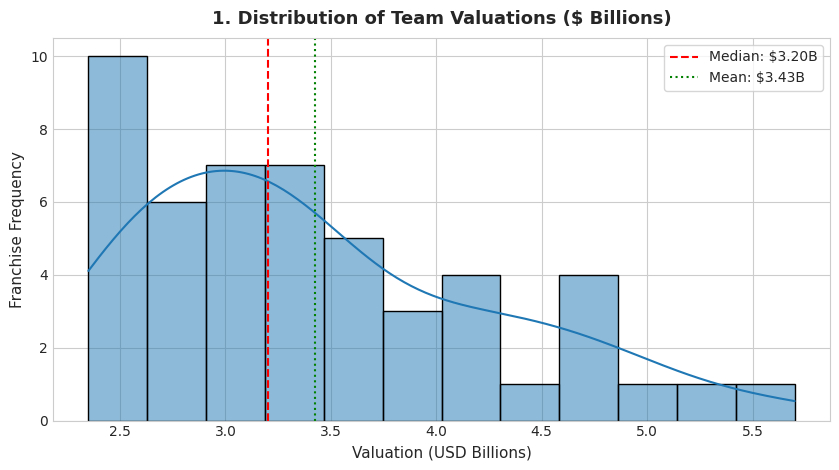

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.histplot(df_clean['Value_USD_B'], kde=True, bins=12, color='#1f77b4', edgecolor='black', ax=ax)
ax.set_title("1. Distribution of Team Valuations ($ Billions)", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Valuation (USD Billions)", fontsize=11)
ax.set_ylabel("Franchise Frequency", fontsize=11)
ax.axvline(df_clean['Value_USD_B'].median(), color='red', linestyle='--', label=f"Median: ${df_clean['Value_USD_B'].median():.2f}B")
ax.axvline(df_clean['Value_USD_B'].mean(), color='green', linestyle=':', label=f"Mean: ${df_clean['Value_USD_B'].mean():.2f}B")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


### 2. Valuation by Sport Category (Box Plot + Stripplot)
**Empirical Inference:**
> NFL (American Football) maintains the highest median valuation and remarkable consistency due to revenue parity and collective media agreements. In contrast, Soccer features a wide interquartile range with elite European clubs competing at the $4B+ apex.

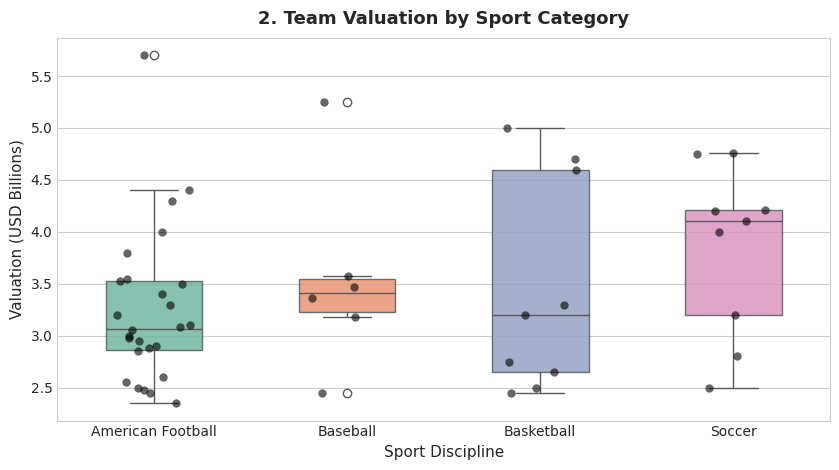

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.boxplot(data=df_clean, x='Sport', y='Value_USD_B', hue='Sport', palette='Set2', legend=False, width=0.5, boxprops=dict(alpha=0.85), ax=ax)
sns.stripplot(data=df_clean, x='Sport', y='Value_USD_B', color='black', alpha=0.6, jitter=0.2, size=6, ax=ax)
ax.set_title("2. Team Valuation by Sport Category", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Sport Discipline", fontsize=11)
ax.set_ylabel("Valuation (USD Billions)", fontsize=11)
plt.tight_layout()
plt.show()


### 3. Top 10 Most Valuable Sports Franchises (Horizontal Bar Chart)
**Empirical Inference:**
> Dallas Cowboys claim the pinnacle ($5.70B), followed by New York Yankees ($5.25B) and New York Knicks ($5.00B). American franchises capture 7 of the top 10 positions, while European football giants Barcelona ($4.76B) and Real Madrid ($4.75B) anchor the global contingent.

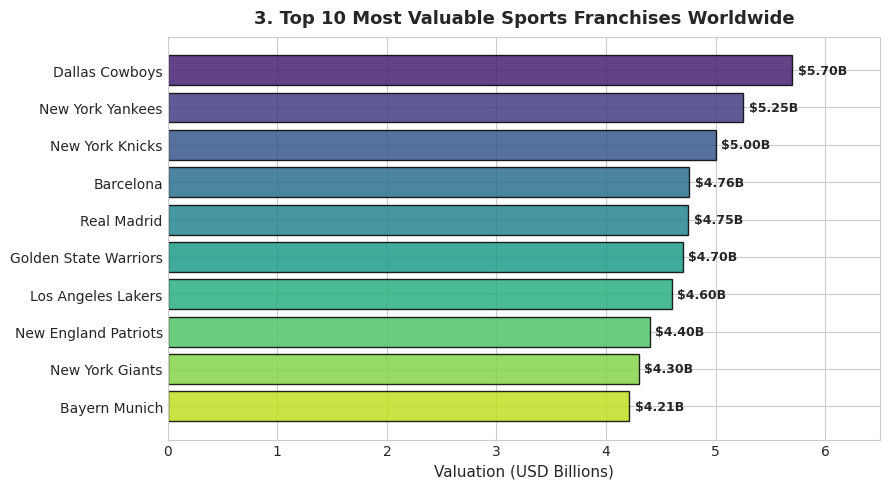

In [8]:
top10 = df_clean.sort_values(by='Value_USD_B', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 5))
colors = sns.color_palette("viridis", len(top10))
bars = ax.barh(top10['Team_Name'], top10['Value_USD_B'], color=colors, edgecolor='black', alpha=0.85)
ax.invert_yaxis()
ax.set_title("3. Top 10 Most Valuable Sports Franchises Worldwide", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Valuation (USD Billions)", fontsize=11)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"${w:.2f}B", ha='left', va='center', fontsize=9, fontweight='bold')
ax.set_xlim(0, 6.5)
plt.tight_layout()
plt.show()


### 4. Franchise Representation Share by Sport (Donut Chart)
**Empirical Inference:**
> American Football (NFL) accounts for an overwhelming 52.0% (26 of 50) of the globe's premier sports properties. Basketball (NBA) holds 18.0%, Soccer accounts for 18.0%, and Baseball (MLB) represents 12.0%, proving the commercial heft of US gridiron football.

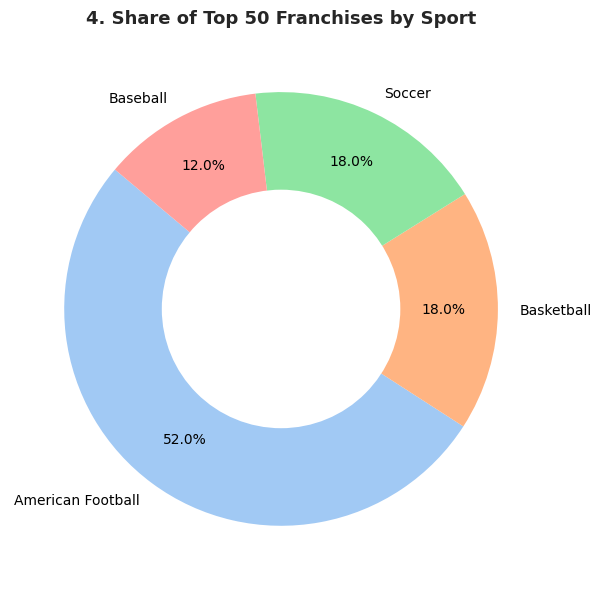

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
sport_counts = df_clean['Sport'].value_counts()
colors = sns.color_palette("pastel")[0:len(sport_counts)]
wedges, texts, autotexts = ax.pie(
    sport_counts, labels=sport_counts.index, autopct='%1.1f%%',
    startangle=140, colors=colors, pctdistance=0.75,
    textprops=dict(color="black", fontsize=10)
)
centre_circle = plt.Circle((0,0), 0.55, fc='white')
ax.add_artist(centre_circle)
ax.set_title("4. Share of Top 50 Franchises by Sport", fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


### 5. Acquisition Price vs. Current Valuation (Scatter Plot + Trendline)
**Empirical Inference:**
> Franchises acquired at modest baseline prices (<$300M in the 20th century) show dramatic multi-thousand-percent capital gains. Newer transactions above $1.5B show contemporary institutional pricing, resulting in higher nominal capital outlays.

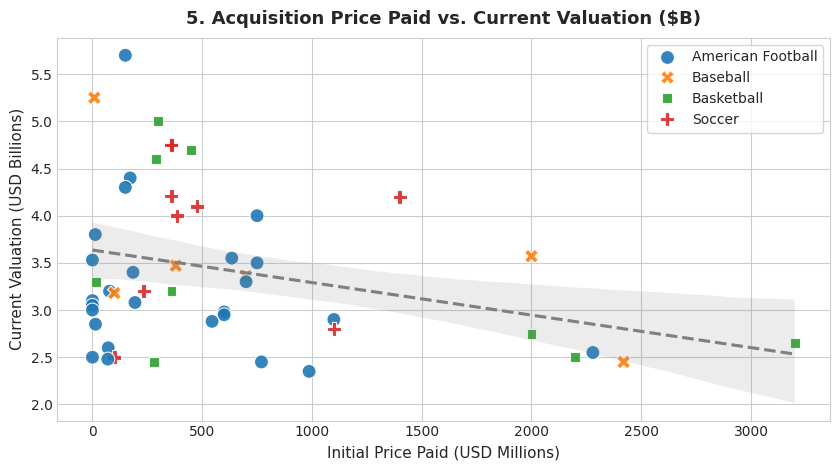

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.scatterplot(
    data=df_clean, x='Price_Paid_USD_M', y='Value_USD_B', hue='Sport',
    style='Sport', s=100, alpha=0.9, palette='tab10', ax=ax
)
sns.regplot(data=df_clean, x='Price_Paid_USD_M', y='Value_USD_B', scatter=False, ax=ax, color='gray', line_kws={'linestyle':'--'})
ax.set_title("5. Acquisition Price Paid vs. Current Valuation ($B)", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Initial Price Paid (USD Millions)", fontsize=11)
ax.set_ylabel("Current Valuation (USD Billions)", fontsize=11)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


### 6. Pearson Correlation Matrix (Heatmap)
**Empirical Inference:**
> Years Held exhibits a strong negative correlation with Year Purchased (-1.00) and a moderate negative correlation with Price Paid (-0.57), verifying inflation and skyrocketing franchise values over successive ownership eras. Value correlates weakly with 5-year growth (-0.04), indicating mature market resilience.

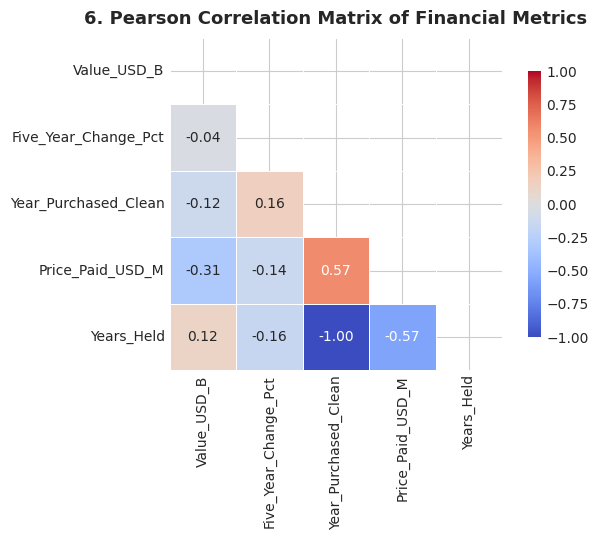

In [11]:
num_cols = ['Value_USD_B', 'Five_Year_Change_Pct', 'Year_Purchased_Clean', 'Price_Paid_USD_M', 'Years_Held']
corr = df_clean[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
    square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax
)
ax.set_title("6. Pearson Correlation Matrix of Financial Metrics", fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


### 7. 5-Year Valuation Growth Distribution (Violin Plot)
**Empirical Inference:**
> Soccer and select NBA teams show wide, tall violin profiles with long tails extending past 150%-200% growth (e.g., PSG at 207%, Liverpool at 165%), driven by international branding. The NFL exhibits a compact bell distribution clustered tightly around 50%-65%.

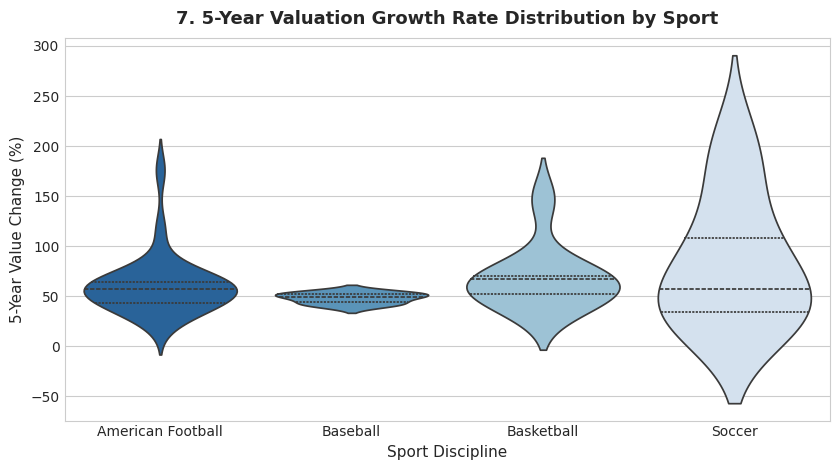

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.violinplot(data=df_clean, x='Sport', y='Five_Year_Change_Pct', hue='Sport', palette='Blues_r', legend=False, inner='quartile', ax=ax)
ax.set_title("7. 5-Year Valuation Growth Rate Distribution by Sport", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Sport Discipline", fontsize=11)
ax.set_ylabel("5-Year Value Change (%)", fontsize=11)
plt.tight_layout()
plt.show()


### 8. Multivariate Pairwise Feature Matrix (Pair Plot)
**Empirical Inference:**
> Bivariate distributions demonstrate distinct cluster boundaries: Soccer occupies the high-growth perimeter, MLB occupies moderate value and moderate acquisition prices, and NFL dominates the central high-density valuation core.

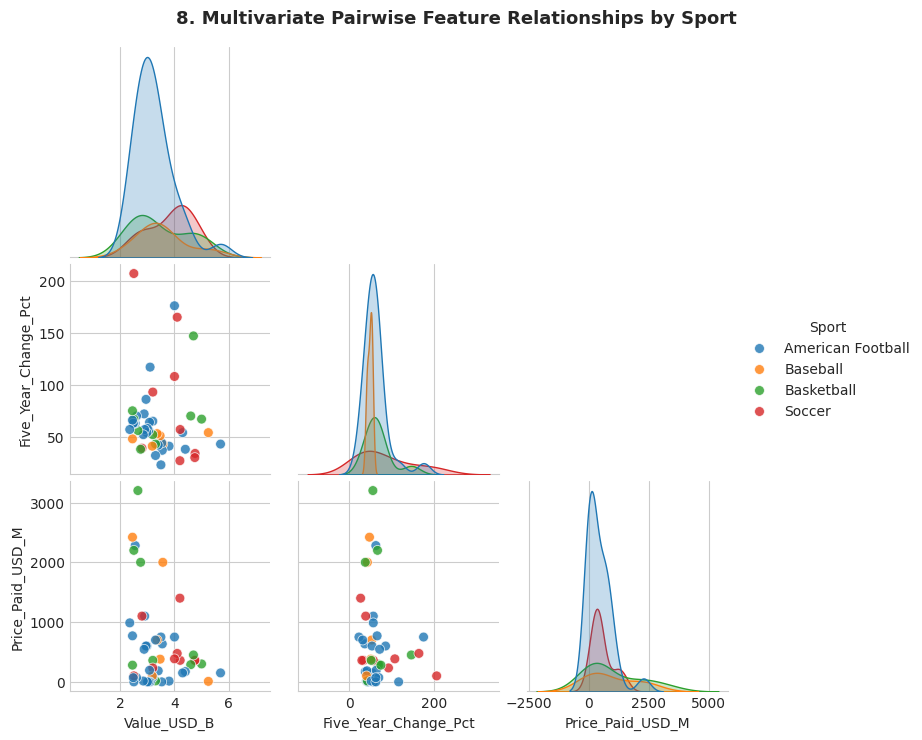

In [13]:
pair_df = df_clean[['Value_USD_B', 'Five_Year_Change_Pct', 'Price_Paid_USD_M', 'Sport']]
g = sns.pairplot(pair_df, hue='Sport', corner=True, palette='tab10', plot_kws={'alpha': 0.8, 's': 50})
g.fig.subplots_adjust(top=0.93)
g.fig.suptitle("8. Multivariate Pairwise Feature Relationships by Sport", fontsize=13, fontweight='bold')
plt.show()


### 9. Valuation & Growth by Purchase Decade (Dual-Axis Line Chart)
**Empirical Inference:**
> Franchises held since the 1920s-1970s maintain remarkably resilient multi-billion-dollar values. Meanwhile, franchises bought during the 2000s and 2010s show accelerated recent 5-year percentage valuation gains due to modernization and global streaming monetization.

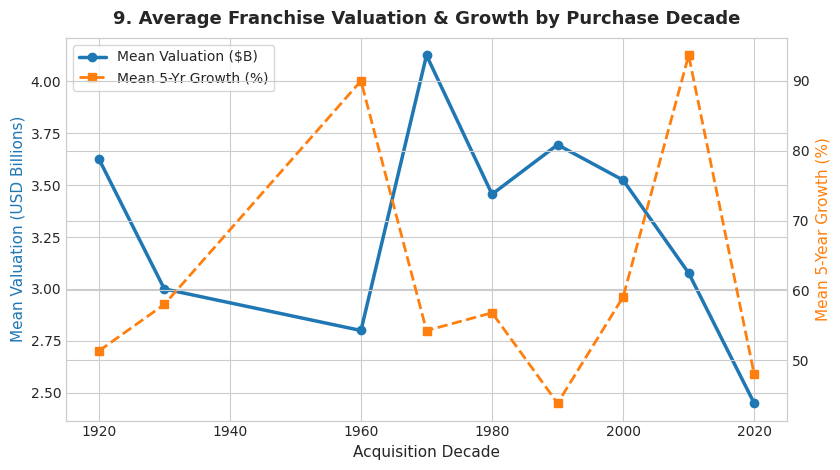

In [14]:
df_sorted_yr = df_clean.sort_values(by='Year_Purchased_Clean').copy()
df_sorted_yr['Decade'] = (df_sorted_yr['Year_Purchased_Clean'] // 10) * 10
decade_trend = df_sorted_yr.groupby('Decade').agg({'Value_USD_B': 'mean', 'Five_Year_Change_Pct': 'mean'}).reset_index()
fig, ax1 = plt.subplots(figsize=(8.5, 4.8))
ax2 = ax1.twinx()
l1 = ax1.plot(decade_trend['Decade'], decade_trend['Value_USD_B'], color='#1f77b4', marker='o', linewidth=2.5, label='Mean Valuation ($B)')
l2 = ax2.plot(decade_trend['Decade'], decade_trend['Five_Year_Change_Pct'], color='#ff7f0e', marker='s', linestyle='--', linewidth=2.0, label='Mean 5-Yr Growth (%)')
ax1.set_title("9. Average Franchise Valuation & Growth by Purchase Decade", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("Acquisition Decade", fontsize=11)
ax1.set_ylabel("Mean Valuation (USD Billions)", color='#1f77b4', fontsize=11)
ax2.set_ylabel("Mean 5-Year Growth (%)", color='#ff7f0e', fontsize=11)
lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 10. Normality Diagnostics (Q-Q Plot and Density Estimation)
**Empirical Inference:**
> The Q-Q plot exhibits pronounced convex curvature at upper quantiles, confirming heavy positive skewness. This violates standard Gaussian assumptions, strongly justifying nonparametric and tree-based data mining methods (such as FP-Growth and Naive Bayes discretization).

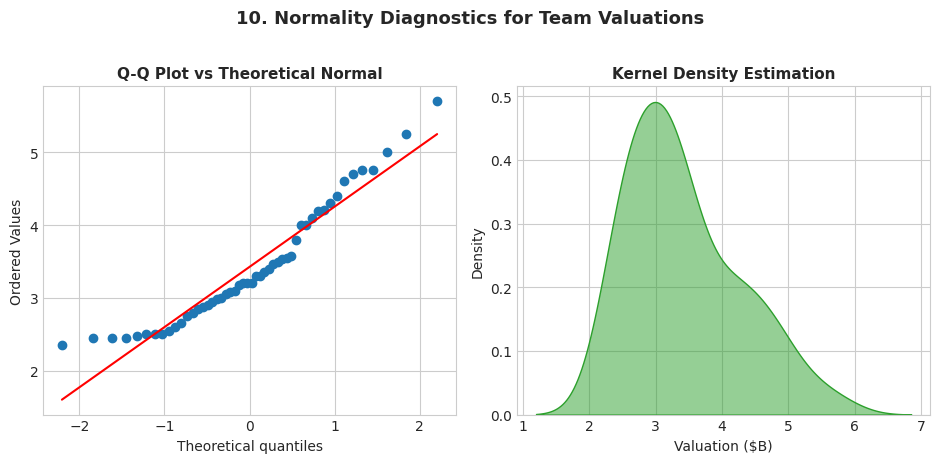

In [15]:
fig, (ax_qq, ax_dens) = plt.subplots(1, 2, figsize=(9.5, 4.5))
stats.probplot(df_clean['Value_USD_B'], dist="norm", plot=ax_qq)
ax_qq.set_title("Q-Q Plot vs Theoretical Normal", fontsize=11, fontweight='bold')
ax_qq.get_lines()[0].set_color('#1f77b4')
ax_qq.get_lines()[1].set_color('red')
sns.kdeplot(df_clean['Value_USD_B'], fill=True, color='#2ca02c', alpha=0.5, ax=ax_dens)
ax_dens.set_title("Kernel Density Estimation", fontsize=11, fontweight='bold')
ax_dens.set_xlabel("Valuation ($B)")
fig.suptitle("10. Normality Diagnostics for Team Valuations", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 11. Geographic Country Distribution by Sport (Stacked Bar Chart)
**Empirical Inference:**
> American Football, Baseball, and Basketball are 100% geographically concentrated in the USA. Conversely, the Soccer category is partitioned across the UK (5 teams), Spain (2 teams), Germany (1 team), and France (1 team), illustrating Europe's polycentric soccer landscape.

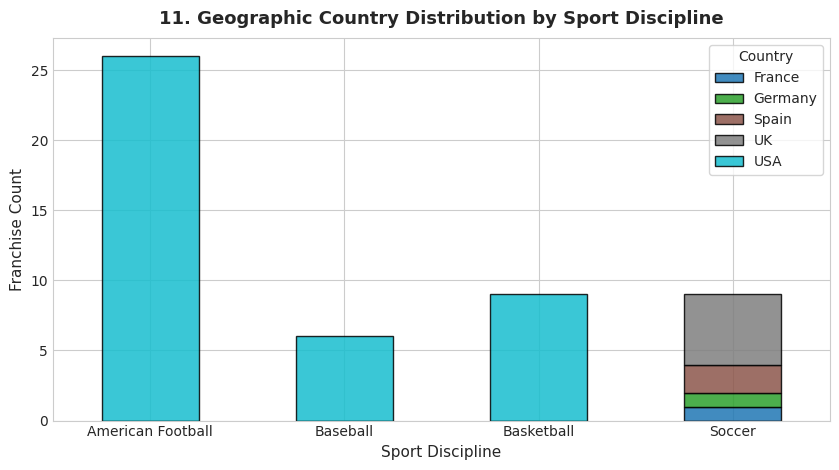

In [16]:
cross_sport_country = pd.crosstab(df_clean['Sport'], df_clean['Country'])
fig, ax = plt.subplots(figsize=(8.5, 4.8))
cross_sport_country.plot(kind='bar', stacked=True, colormap='tab10', ax=ax, edgecolor='black', alpha=0.85)
ax.set_title("11. Geographic Country Distribution by Sport Discipline", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Sport Discipline", fontsize=11)
ax.set_ylabel("Franchise Count", fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Country", frameon=True)
plt.tight_layout()
plt.show()


### 12. Valuation vs. 5-Year Growth (Bubble Chart, Size = Years Held)
**Empirical Inference:**
> Franchises held for decades (largest bubbles) occupy the upper valuation plateau with steady compound gains. Outlying high-growth properties (e.g., Golden State Warriors, LA Rams, PSG) are medium-sized bubbles purchased in the modern era, capturing rapid franchise re-evaluations.

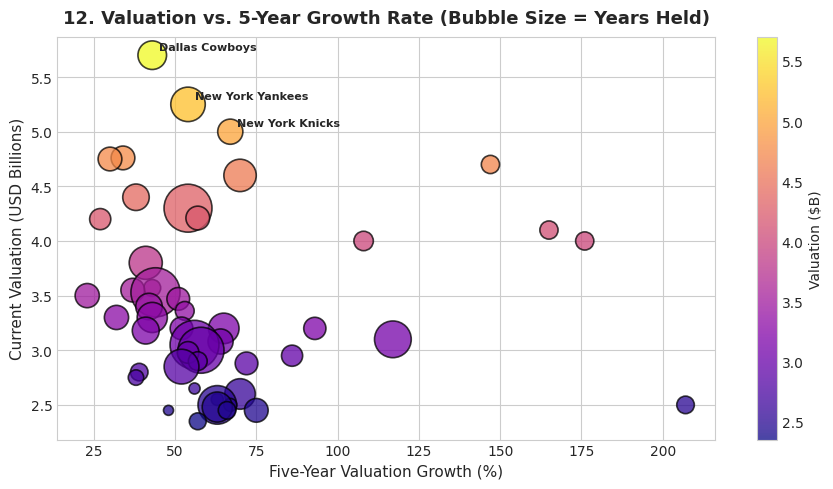

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
scatter = ax.scatter(
    df_clean['Five_Year_Change_Pct'], df_clean['Value_USD_B'],
    s=df_clean['Years_Held'] * 12 + 40,
    c=df_clean['Value_USD_B'], cmap='plasma', alpha=0.75, edgecolors='black', linewidth=1.2
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Valuation ($B)", fontsize=10)
ax.set_title("12. Valuation vs. 5-Year Growth Rate (Bubble Size = Years Held)", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Five-Year Valuation Growth (%)", fontsize=11)
ax.set_ylabel("Current Valuation (USD Billions)", fontsize=11)
for idx, row in df_clean.nlargest(3, 'Value_USD_B').iterrows():
    ax.annotate(row['Team_Name'], (row['Five_Year_Change_Pct'] + 2, row['Value_USD_B'] + 0.05), fontsize=8, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Transition to Phase 4: Data Mining & Predictive Modeling
Phases 1 through 3 have established the cleaned, scaled, and binned datasets (`clean.csv`, `scaled.csv`, `transactions.csv`).  
In Phase 4, the pipeline proceeds to:
1. **FP-Growth Rule Mining:** Frequent itemsets and association rules (`min_support=0.10`, `min_confidence=0.60`).
2. **CHARM Closed Itemset Mining:** Custom IT-tree CFI algorithm and compression ratio quantification.
3. **Naive Bayes Classification:** Probabilistic tier prediction (`High`, `Med`, `Low`) with 80/20 train/test evaluation.
4. **AGNES Hierarchical Clustering:** Agglomerative clustering with Ward linkage dendrogram, cophenetic correlation, and silhouette score.
